# Corporate early-warning research review

Benchmark results are measured. Indian historical recall is withheld pending complete verified evidence. Run the pipeline before this notebook; the notebook reads saved results and does not tune on the test set.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'results/benchmark/metrics.json').exists():
    ROOT=Path('credit-ews')
metrics=json.loads((ROOT/'results/benchmark/metrics.json').read_text())
readiness=json.loads((ROOT/'results/india/readiness.json').read_text())
display(pd.DataFrame([{'metric':k,'value':v} for k,v in metrics['holdout'].items() if not isinstance(v,(dict,list))]))

,metric,value
0,sample_count,1170.000000
1,positive_count,81.000000
2,average_precision,0.397586
3,pr_auc_trapezoidal,0.393355
4,roc_auc,0.851138
5,brier_score,0.051344
6,prevalence,0.069231


## Benchmark validation

The split groups on the actual deployed financial vectors. AP and trapezoidal PR-AUC are separately reported.

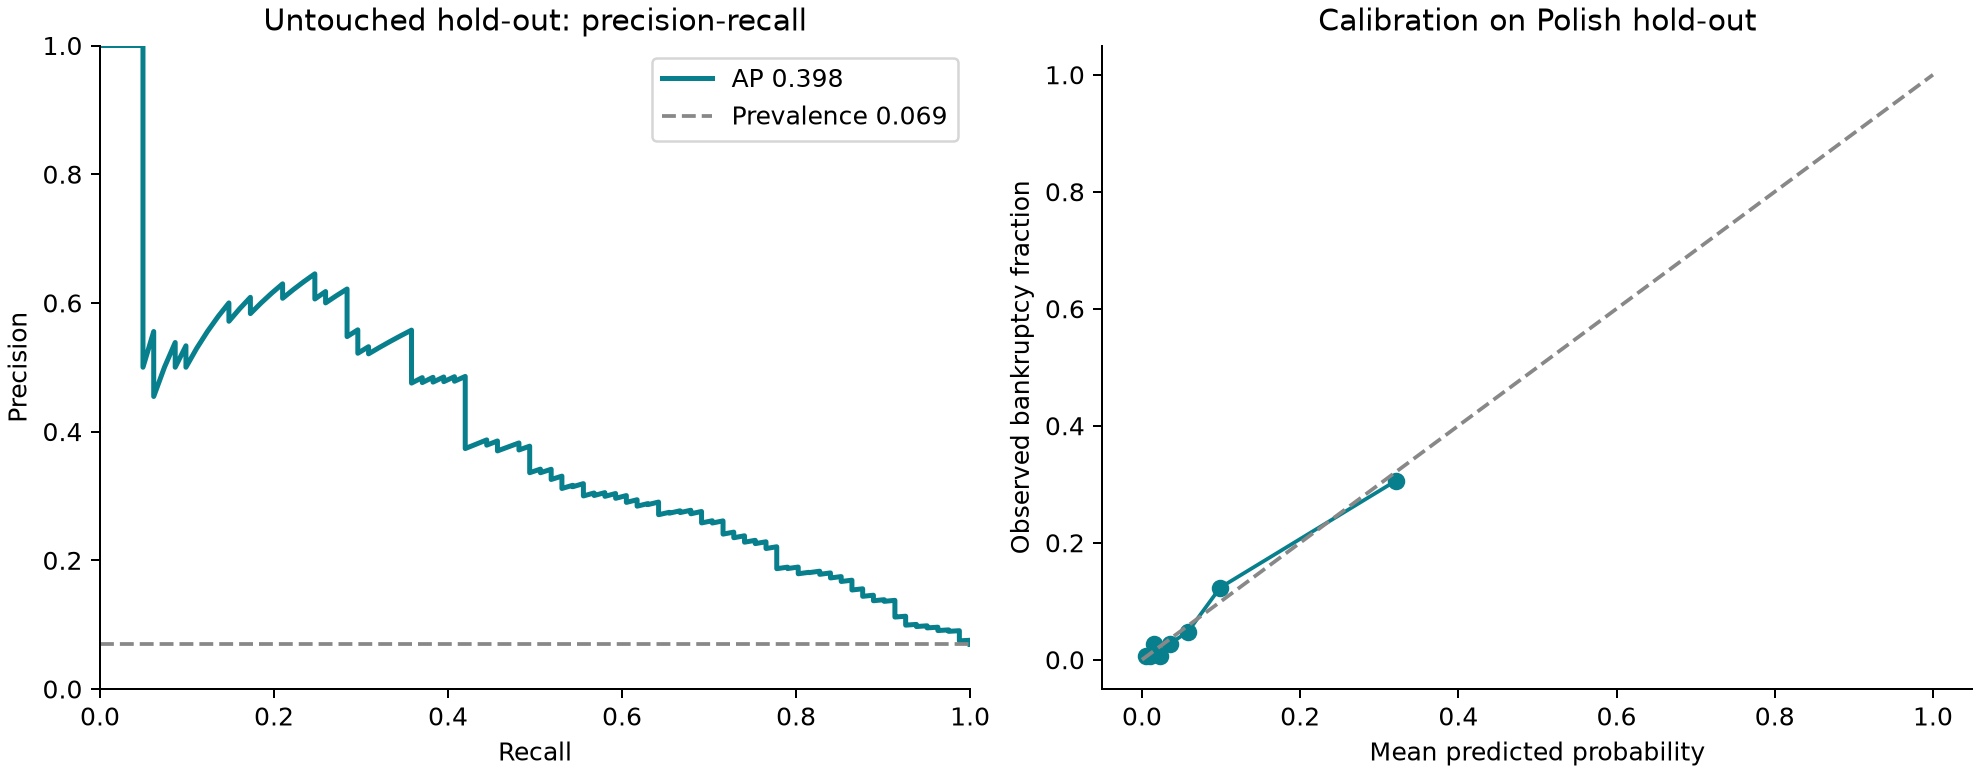

,row_id,label,score,top5_selected,cost_policy_selected
0,7,0,0.002879,False,False
1,12,0,0.104772,False,False
2,17,0,0.021938,False,False
3,18,0,0.018844,False,False
4,42,0,0.008413,False,False
5,43,0,0.075878,False,False
6,45,0,0.005743,False,False
7,60,0,0.038620,False,False
8,64,0,0.006603,False,False
9,65,0,0.047038,False,False


In [2]:
display(Image(filename=str(ROOT/'results/benchmark/benchmark-validation.png')))
display(pd.read_csv(ROOT/'results/benchmark/holdout_predictions.csv').head(10))

## Development choices

This table contains development cross-validation results, not repeated model selection on hold-out scores.

In [3]:
comparison=json.loads((ROOT/'results/benchmark/development_comparison.json').read_text())
display(pd.json_normalize(comparison)[['config.kind','config.balanced','average_precision','top5.recall','top5.cost']])

,config.kind,config.balanced,average_precision,top5.recall,top5.cost
0,logistic,False,0.311382,0.305810,4674
1,logistic,True,0.301246,0.272171,4905
2,logistic,False,0.310164,0.308869,4653
3,logistic,True,0.301372,0.278287,4863
4,logistic,False,0.310220,0.305810,4674
5,logistic,True,0.301045,0.278287,4863
6,hist_boost,False,0.381337,0.348624,4380
7,hist_boost,True,0.369774,0.345566,4401
8,hist_boost,False,0.412425,0.348624,4380
9,hist_boost,True,0.388424,0.330275,4506


## Readiness and remaining evidence

A candidate roster and downloaded reports do not establish a complete Indian panel.

In [4]:
display(pd.DataFrame([{'item':k,'value':v} for k,v in readiness.items() if not isinstance(v,list)]))
display(pd.read_csv(ROOT/'results/india/coverage_review_queue.csv'))

,item,value
0,status,research_build_incomplete_for_competition_subm...
1,benchmark_complete,True
2,downloaded_documents,196
3,failed_document_routes,13
4,core_case_candidates,10
5,core_peer_candidates,30
6,documented_cirp_dates,10
7,documented_earlier_payment_default_cases,5
8,automatically_extracted_candidate_rows,4309
9,source_reviewed_issuers_all_groups,8


,entity_id,name,role,downloaded_annual_reports,extraction_candidate_rows,reviewed_source_versions,reviewed_distinct_periods,strict_point_in_time_accounts,missing_gate
0,BHUSHAN,Bhushan Steel,case,7,78,4,3,0,publication_dates; annual ratio coverage; cont...
1,MONNET,Monnet Ispat & Energy,case,3,91,0,0,0,publication_dates; annual ratio coverage; cont...
2,ALOK,Alok Industries,case,4,102,0,0,0,publication_dates; annual ratio coverage; cont...
3,AMTEK,Amtek Auto,case,5,140,0,0,0,publication_dates; annual ratio coverage; cont...
4,LANCO,Lanco Infratech,case,3,90,0,0,0,publication_dates; annual ratio coverage; cont...
5,JAYPEE,Jaypee Infratech,case,3,85,0,0,0,publication_dates; annual ratio coverage; cont...
6,JYOTI,Jyoti Structures,case,3,103,0,0,0,publication_dates; annual ratio coverage; cont...
7,ELECTROSTEEL,Electrosteel Steels,case,3,40,0,0,0,publication_dates; annual ratio coverage; cont...
8,ERA,Era Infra Engineering,case,2,48,0,0,0,publication_dates; annual ratio coverage; cont...
9,FUTURE,Future Retail,case,4,68,0,0,0,publication_dates; annual ratio coverage; cont...


## Indian numerical pilot

These four source-reviewed examples have unverified publication dates. The transferred score is not an Indian PD. A four-name sample has zero formal slots at a strict 5% rate.

In [5]:
display(pd.read_csv(ROOT/'results/india/pilot_scores.csv'))
display(pd.read_csv(ROOT/'results/india/pilot_ratios.csv'))

,entity_id,score,score_type,altman_z_double_prime,outside_training_clip_range,rank,selected,capacity,status
0,ITNL,0.103447,transferred_Polish_risk_score_not_calibrated_I...,0.616839,0,1,False,0,evidence_pilot_only_publication_dates_pending
1,ASHOKA,0.064849,transferred_Polish_risk_score_not_calibrated_I...,0.640577,0,2,False,0,evidence_pilot_only_publication_dates_pending
2,SADBHAV,0.063902,transferred_Polish_risk_score_not_calibrated_I...,0.382956,0,3,False,0,evidence_pilot_only_publication_dates_pending
3,IRB,0.057869,transferred_Polish_risk_score_not_calibrated_I...,0.565291,0,4,False,0,evidence_pilot_only_publication_dates_pending


,entity_id,X1,X2,X3,X4,X6,X7,X8,X9,X20,X23,X44,X46
0,ASHOKA,0.003798,0.846120,0.018545,1.201669,0.045442,0.032754,0.143505,0.169878,152.027793,0.022358,51.099878,0.432201
1,IRB,0.015074,0.884718,-0.016085,0.790787,0.069731,0.045784,0.129353,0.121624,21.973059,0.123936,7.375276,0.695558
2,ITNL,0.008232,0.810620,-0.050695,0.735130,0.059723,0.078215,0.218186,0.218363,3.840459,0.037699,57.341438,0.723125
3,SADBHAV,-0.002957,0.854270,-0.007809,0.937475,0.011704,0.038132,0.133120,0.245272,13.277091,-0.012058,77.353118,0.866037


## Inspect a credit evidence card

Change the entity identifier to inspect another reviewed example. The SHAP values explain the actual displayed score.

In [6]:
entity='ITNL'
cards=json.loads((ROOT/'results/india/pilot_evidence_cards.json').read_text())
card=next(c for c in cards if c['entity_id']==entity)
display(pd.DataFrame(card['drivers']))
display(pd.read_csv(ROOT/'data/curated/pilot_field_sources.csv').query('entity_id == @entity'))
print('M-Score missing inputs:',card['beneish_m']['missing'])
print('F-Score missing inputs:',card['piotroski_f']['missing'])

,feature,label,value,score_contribution,direction,credit_interpretation,source_document_id,caution
0,X6,Retained earnings / assets,0.059723,0.032768,raises,This observed value raises the model score rel...,ITNL_2016_annual,Association relative to Polish training backgr...
1,X9,Sales / assets,0.218363,0.024927,raises,This observed value raises the model score rel...,ITNL_2016_annual,Association relative to Polish training backgr...
2,X20,Inventory days relative to sales,3.840459,0.016889,raises,This observed value raises the model score rel...,ITNL_2016_annual,Association relative to Polish training backgr...


,entity_id,period_end,field,value,normalized_unit,source_document_id,source_url,pdf_page,verification_status,publication_status,note
0,ITNL,2016-03-31,total_assets,37844.29,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,179,reviewed_numeric_source,unverified,NaN
1,ITNL,2016-03-31,current_assets,5324.75,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,179,reviewed_numeric_source,unverified,NaN
2,ITNL,2016-03-31,current_liabilities,7243.28,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,179,reviewed_numeric_source,unverified,NaN
3,ITNL,2016-03-31,equity,6693.35,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,179,reviewed_numeric_source,unverified,NaN
4,ITNL,2016-03-31,minority_interest,473.61,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,179,reviewed_numeric_source,unverified,NaN
5,ITNL,2016-03-31,retained_earnings,2260.18,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,197,reviewed_numeric_source,unverified,Reconstructed accumulated earnings: P&L surplu...
6,ITNL,2016-03-31,net_income,311.54,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,180,reviewed_numeric_source,unverified,NaN
7,ITNL,2016-03-31,sales,8263.79,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,180,reviewed_numeric_source,unverified,NaN
8,ITNL,2016-03-31,inventory,86.95,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,179,reviewed_numeric_source,unverified,NaN
9,ITNL,2016-03-31,receivables,1298.24,INR crore,ITNL_2016_annual,https://www.bseindia.com/bseplus/AnnualReport/...,179,reviewed_numeric_source,unverified,NaN


M-Score missing inputs: ['current.cogs', 'current.sga', 'prior.cogs', 'prior.sga', 'current.income_continuing_operations']
F-Score missing inputs: ['positive_roa', 'improving_roa', 'cash_above_earnings', 'lower_leverage', 'no_equity_issue', 'higher_gross_margin', 'higher_asset_turnover']


## Events and original documents

First-default reconstruction must precede the early-warning claim. Month intervals remain intervals.

In [7]:
display(pd.read_csv(ROOT/'data/curated/events.csv'))
from ews.evidence import load_documents
docs=load_documents(ROOT)
display(docs[['document_id','status','source_url','sha256','publication_status']].head(20))

,entity_id,event_type,date_lower,date_upper,date_precision,verification_status,source_document_id,pdf_page,source_url,first_default_status,usable_as_feature,review_note
0,BHUSHAN,cirp_admission,2017-07-26,2017-07-26,day,documented,REGISTRY_2017_event,11,https://ibbi.gov.in/uploads/meetings/Agenda_7%...,not_established,False,NaN
1,MONNET,cirp_admission,2017-07-18,2017-07-18,day,documented,REGISTRY_2017_event,11,https://ibbi.gov.in/uploads/meetings/Agenda_7%...,not_established,False,NaN
2,ALOK,cirp_admission,2017-07-18,2017-07-18,day,documented,REGISTRY_2017_event,11,https://ibbi.gov.in/uploads/meetings/Agenda_7%...,not_established,False,NaN
3,AMTEK,cirp_admission,2017-07-24,2017-07-24,day,documented,REGISTRY_2017_event,11,https://ibbi.gov.in/uploads/meetings/Agenda_7%...,not_established,False,NaN
4,LANCO,cirp_admission,2017-08-07,2017-08-07,day,documented,REGISTRY_2017_event,11,https://ibbi.gov.in/uploads/meetings/Agenda_7%...,not_established,False,NaN
5,JAYPEE,cirp_admission,2017-08-09,2017-08-09,day,documented,REGISTRY_2017_event,11,https://ibbi.gov.in/uploads/meetings/Agenda_7%...,not_established,False,NaN
6,JYOTI,cirp_admission,2017-07-04,2017-07-04,day,documented,REGISTRY_2017_event,11,https://ibbi.gov.in/uploads/meetings/Agenda_7%...,not_established,False,NaN
7,ELECTROSTEEL,cirp_admission,2017-07-21,2017-07-21,day,documented,REGISTRY_2017_event,11,https://ibbi.gov.in/uploads/meetings/Agenda_7%...,not_established,False,NaN
8,ERA,cirp_admission,2018-05-08,2018-05-08,day,documented,ERA_2018_event,2,https://ibbi.gov.in/uploads/order/eba413347ca8...,not_established,False,NaN
9,FUTURE,cirp_admission,2022-07-20,2022-07-20,day,documented,FUTURE_2022_event,1,https://www.bseindia.com/xml-data/corpfiling/A...,not_established,False,NaN


,document_id,status,source_url,sha256,publication_status
0,ALOK_2012_annual,downloaded,https://www.bseindia.com/bseplus/AnnualReport/...,d921d20620cfe20bef3acbb919cbe69e597b27c8fa39c8...,unverified
1,ALOK_2013_annual,downloaded,https://www.bseindia.com/bseplus/AnnualReport/...,5739b14f41ae05fd481af284560f88c1afbd0e0cb5c383...,unverified
2,ALOK_2014_annual,failed,https://www.bseindia.com/bseplus/AnnualReport/...,,unverified
3,ALOK_2015_annual,downloaded,https://www.bseindia.com/bseplus/AnnualReport/...,5dfc045cf01461a7489187775fbd30e9e27f9bd96eed8d...,unverified
4,ALOK_2016_annual,downloaded,https://www.bseindia.com/bseplus/AnnualReport/...,cdb4c82e5f3090c8e320c1836d6f86aa41f02089c2ab6b...,unverified
5,AMTEK_2012_annual,downloaded,https://www.bseindia.com/bseplus/AnnualReport/...,5d75faeb5e17725ddf3bae9e86da2da2b41bce9cf90f2b...,unverified
6,AMTEK_2013_annual,downloaded,https://www.bseindia.com/bseplus/AnnualReport/...,710476066f454d71cbbacf32f92068a1e32b30595d4821...,unverified
7,AMTEK_2014_annual,downloaded,https://www.bseindia.com/bseplus/AnnualReport/...,4fb183bca0170c5238e1e07ae19feeb468863c3f480602...,unverified
8,AMTEK_2015_annual,downloaded,https://www.bseindia.com/bseplus/AnnualReport/...,cb6dc1115aa98c829ac4b74b8719258f08710e7dc31fdd...,unverified
9,AMTEK_2016_annual,downloaded,https://www.bseindia.com/bseplus/AnnualReport/...,c81be1966f279e0f1c8eee5734e3f30faf34a97fe4d5f4...,unverified


## Primary historical replay

The engine requires approved population and accounting inputs. Read docs/DATA_REVIEW.md for the schemas.

In [8]:
print((ROOT/'results/india/primary/status.json').read_text())

{
  "status": "not_run",
  "reason": "Approved full population and publication-verified accounts not yet supplied; draft candidates are excluded.",
  "required_inputs": [
    "data/curated/approved_population.csv",
    "data/curated/approved_accounts.csv"
  ]
}


## Bhushan Steel dossier

The FY2012 peer comparison is exploratory. First-default dates conflict, public timestamps are unverified, and earned-reserve mappings remain proxies. FY2011 comparative figures from FY2012 sources are excluded from the eight-quarter cutoffs.

In [9]:
case=ROOT/'results/india/bhushan-case'
display(pd.read_csv(case/'fy2012_peer_comparison.csv'))
display(pd.read_csv(case/'lead_time_scenarios.csv'))
print((case/'status.json').read_text())
display(pd.read_csv(ROOT/'data/curated/bhushan_case_events.csv'))

,entity_id,period_end,source_document_id,source_column,score,altman_z_double_prime_proxy,formal_alert,primary_eligible,descriptive_rank
0,BHUSHAN,2012-03-31,BHUSHAN_2012_annual,current,0.059109,0.828029,False,False,1
1,JSW,2012-03-31,JSW_2012_annual,current,0.054175,0.514927,False,False,2
2,TATASTEEL,2012-03-31,TATASTEEL_2012_annual,current,0.024554,2.055794,False,False,3
3,SAIL,2012-03-31,SAIL_2012_annual,current,0.016826,3.931284,False,False,4


,entity_id,event_scenario,event_status,lead_months,cutoff,strict_status,strict_score,sensitivity_status,sensitivity_period_end,sensitivity_source_document_id,sensitivity_score,formal_alert,recovered
0,BHUSHAN,2013-12-31,earliest documented payment failure; contempor...,12,2012-12-31,withheld_unverified_publication_and_endpoint,NaN,AGM_assumption_only_mapping_pending,2012-03-31,BHUSHAN_2012_annual,0.059109,False,NaN
1,JSW,2013-12-31,earliest documented payment failure; contempor...,12,2012-12-31,withheld_unverified_publication_and_endpoint,NaN,AGM_assumption_only_mapping_pending,2012-03-31,JSW_2012_annual,0.054175,False,NaN
2,TATASTEEL,2013-12-31,earliest documented payment failure; contempor...,12,2012-12-31,withheld_unverified_publication_and_endpoint,NaN,AGM_assumption_only_mapping_pending,2012-03-31,TATASTEEL_2012_annual,0.024554,False,NaN
3,SAIL,2013-12-31,earliest documented payment failure; contempor...,12,2012-12-31,withheld_unverified_publication_and_endpoint,NaN,AGM_assumption_only_mapping_pending,2012-03-31,SAIL_2012_annual,0.016826,False,NaN
4,BHUSHAN,2013-12-31,earliest documented payment failure; contempor...,24,2011-12-31,withheld_unverified_publication_and_endpoint,NaN,withheld_no_eligible_source_version,NaN,NaN,NaN,False,NaN
5,JSW,2013-12-31,earliest documented payment failure; contempor...,24,2011-12-31,withheld_unverified_publication_and_endpoint,NaN,withheld_no_eligible_source_version,NaN,NaN,NaN,False,NaN
6,TATASTEEL,2013-12-31,earliest documented payment failure; contempor...,24,2011-12-31,withheld_unverified_publication_and_endpoint,NaN,withheld_no_eligible_source_version,NaN,NaN,NaN,False,NaN
7,SAIL,2013-12-31,earliest documented payment failure; contempor...,24,2011-12-31,withheld_unverified_publication_and_endpoint,NaN,withheld_no_eligible_source_version,NaN,NaN,NaN,False,NaN
8,BHUSHAN,2014-04-01,later retrospective assertion with date incons...,12,2013-03-31,withheld_unverified_publication_and_endpoint,NaN,AGM_assumption_only_mapping_pending,2012-03-31,BHUSHAN_2012_annual,0.059109,False,NaN
9,JSW,2014-04-01,later retrospective assertion with date incons...,12,2013-03-31,withheld_unverified_publication_and_endpoint,NaN,AGM_assumption_only_mapping_pending,2012-03-31,JSW_2012_annual,0.054175,False,NaN


{
  "status": "case_dossier_completed_with_material_unresolved_evidence",
  "numeric_examples": 9,
  "reviewed_issuers": 4,
  "first_default_status": "earliest_documented_not_exhaustively_established",
  "primary_replay_status": "withheld",
  "strict_recall_4q": null,
  "strict_recall_8q": null,
  "formal_capacity_slots": 0,
  "assumptions": [
    "AGM report circulation is sensitivity only; no verified historical public timestamp.",
    "Retained earnings is a disclosed core proxy; classification approval pending.",
    "Peers remain provisional; historical nondefault follow-up not certified."
  ],
  "main_finding": "Frozen FY2012 model ranks BHUSHAN 1 of 4; no model tuning or success claim.",
  "downloaded_additional_sources": 27,
  "failed_additional_routes": 9,
  "source_integrity_checked": 27,
  "source_integrity_not_cached": 0
}


,entity_id,event_type,date_lower,date_upper,date_precision,verification_status,source_document_id,pdf_page,first_default_status,usable_as_feature,review_note,source_url
0,BHUSHAN,documented_earlier_payment_default,2013-12-31,2013-12-31,day,corroborated_contemporaneous_indexed_primary,AXIS_2015_halfyear_defaults,16,earliest_documented_not_exhaustively_established,False,"Contemporary Jan16,2014 indexed trustee entry ...",https://www.axistrustee.in/pdf/SEBI-Half-Yearl...
1,BHUSHAN,retrospective_default_date_assertion,2014-04-01,2014-04-01,day,source_verified_assertion_unresolved,AXIS_2015_halfyear_defaults,16,unresolved_conflicting_primary_evidence,False,"Later trustee text says Apr2014, whereas other...",https://www.axistrustee.in/pdf/SEBI-Half-Yearl...
2,BHUSHAN,documented_earlier_payment_default,2014-08-26,2014-08-26,day,documented,AXIS_2014_sep_defaults,12,unresolved_conflicting_primary_evidence,False,"Rs175 crore NCD missed interest, September2014...",https://www.axistrustee.in/pdf/AT-IR-Issuer-Co...
3,BHUSHAN,security_creation_delay_not_payment_default,2013-12-02,2013-12-02,day,documented,AXIS_2014_sep_defaults,2,unresolved_conflicting_primary_evidence,False,Rs200 crore instrument complete-security deadl...,https://www.axistrustee.in/pdf/AT-IR-Issuer-Co...
4,BHUSHAN,auditor_no_default_statement_financial_year_end,2014-03-31,2014-03-31,day,documented,BHUSHAN_2014_annual,31,unresolved_conflicting_primary_evidence,False,CARO clause xi states no default to financial ...,https://www.bseindia.com/bseplus/AnnualReport/...


## Original FY2011 and payment reconciliation

Original reports remain distinct from later comparative versions. A documented payment event is not an exhaustive first-default certification, and filing/signature/archive metadata do not automatically establish public availability.

In [10]:
recon=ROOT/'results/india/bhushan-reconciliation'
display(pd.read_csv(recon/'gross_balance_reconciliation.csv'))
display(pd.read_csv(recon/'original_vs_later_comparatives.csv'))
display(pd.read_csv(ROOT/'data/curated/reconciled_payment_episodes.csv'))
display(pd.read_csv(ROOT/'data/curated/fy2011_availability_review.csv'))
print((recon/'status.json').read_text())

,entity_id,period_end,source_document_id,gross_assets,liabilities,parent_funds,other_equity,residual_crore,model_eligible,publication_verified
0,BHUSHAN,2011-03-31,BHUSHAN_2011_annual,25325.799,19396.7184,5900.0193,29.0613,-3.637979e-12,False,False
1,JSW,2011-03-31,JSW_2011_annual,46166.530,29401.3700,16529.3300,235.8300,-7.275958e-12,False,False
2,TATASTEEL,2011-03-31,TATASTEEL_2011_annual,135483.140,97512.8700,35563.9100,2406.3600,1.455192e-11,False,False
3,SAIL,2011-03-31,SAIL_2011_annual,78109.970,40492.5800,37604.3100,13.0800,0.000000e+00,False,False


,entity_id,original_field,later_field,original_value,later_comparative_value,delta_later_minus_original,unit,original_source,later_source,original_available_at,later_values_backdated,note
0,BHUSHAN,gross_total_assets,total_assets,25325.7990,25325.7990,0.000000e+00,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...
1,BHUSHAN,gross_total_liabilities,total_liabilities,19396.7184,19396.7184,0.000000e+00,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...
2,BHUSHAN,reported_parent_funds,equity,5900.0193,5908.4556,8.436300e+00,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...
3,BHUSHAN,net_income_parent,net_income,1007.3946,1007.3946,0.000000e+00,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...
4,BHUSHAN,harmonized_operating_revenue,sales,7003.5363,7003.5363,-9.094947e-13,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...
5,BHUSHAN,inventories,inventory,3186.1788,3186.1788,0.000000e+00,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...
6,BHUSHAN,sundry_debtors,receivables,490.0421,490.0421,0.000000e+00,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...
7,BHUSHAN,profit_before_tax,profit_before_tax,1375.7002,1375.7002,0.000000e+00,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...
8,BHUSHAN,core_earned_reserve_proxy,retained_earnings,3561.7041,3561.7041,0.000000e+00,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...
9,BHUSHAN,depreciation,depreciation,277.8591,277.8591,0.000000e+00,INR crore,BHUSHAN_2011_annual,BHUSHAN_2012_annual,NaN,False,Observed source-version/definition difference;...


,entity_id,programme_size_crore,due_date,missed_payment_reported_asof,reported_paid_in_status_asof,actual_settlement_date,isin,event_status,first_default_status,initial_source_document_id,cure_source_document_id,later_corroboration_document_id,later_corroboration_pdf_page,source_url,notes
0,BHUSHAN,500,2013-12-31,2014-01-16,2014-02-26,NaN,NaN,corroborated_contemporaneous_indexed_primary_a...,earliest_documented_not_exhaustively_established,AXIS_2014_jan_payment,AXIS_2014_feb_cure,AXIS_2015_halfyear_defaults,16.0,https://www.axistrustee.in/pdf/Non-Compliance-...,"500crore is the trustee programme label, not u..."
1,BHUSHAN,105,2014-01-01,2014-01-16,NaN,NaN,NaN,contemporaneous_indexed_primary_with_undated_s...,subsequent_to_documented_Dec2013_event,AXIS_2014_jan_payment,AXIS_2014_jan_payment,AXIS_2015_mar_halfyear,NaN,https://www.axistrustee.in/pdf/Non-Compliance-...,Holder email Jan6 and trustee follow-up Jan7 r...
2,BHUSHAN,500,2014-04-01,NaN,NaN,NaN,NaN,retrospective_date_inconsistency_unresolved,cannot_displace_earlier_Dec2013_event,AXIS_2015_halfyear_defaults,NaN,NaN,16.0,https://www.axistrustee.in/pdf/SEBI-Half-Yearl...,Some2015notices nameApr2015in due-date field a...
3,BHUSHAN,175,2014-08-26,2014-09-30,2015-09-30,NaN,NaN,local_original_render_reviewed,subsequent_to_documented_Dec2013_event,AXIS_2014_sep_defaults,AXIS_2015_halfyear_defaults,AXIS_2015_halfyear_defaults,15.0,https://www.axistrustee.in/pdf/AT-IR-Issuer-Co...,Different programme from500crore. Later report...


,entity_id,source_document_id,evidence_type,evidence_date,public_available_at,publication_status,proves,source_url,strict_eligible
0,BHUSHAN,BHUSHAN_2011_annual,auditor_signature,2011-07-29,NaN,unverified,"Statement preparation/signature, not public di...",https://www.bseindia.com/bseplus/AnnualReport/...,False
1,BHUSHAN,BHUSHAN_2011_annual,Internet_Archive_availability_API_for_BSE_URL,NaN,NaN,no_qualifying_capture,Nearest returned capture absent or after relev...,https://archive.org/wayback/available,False
2,JSW,JSW_2011_annual,auditor_signature,2011-05-16,NaN,unverified,"Statement preparation/signature, not public di...",https://www.bseindia.com/bseplus/AnnualReport/...,False
3,JSW,JSW_2011_annual,Internet_Archive_availability_API_for_BSE_URL,NaN,NaN,no_qualifying_capture,Nearest returned capture absent or after relev...,https://archive.org/wayback/available,False
4,TATASTEEL,TATASTEEL_2011_annual,auditor_signature,2011-05-25,NaN,unverified,"Statement preparation/signature, not public di...",https://www.bseindia.com/bseplus/AnnualReport/...,False
5,TATASTEEL,TATASTEEL_2011_annual,Internet_Archive_availability_API_for_BSE_URL,NaN,NaN,no_qualifying_capture,Nearest returned capture absent or after relev...,https://archive.org/wayback/available,False
6,SAIL,SAIL_2011_annual,auditor_signature,2011-08-05,NaN,unverified,"Statement preparation/signature, not public di...",https://www.bseindia.com/bseplus/AnnualReport/...,False
7,SAIL,SAIL_2011_annual,Internet_Archive_availability_API_for_BSE_URL,NaN,NaN,no_qualifying_capture,Nearest returned capture absent or after relev...,https://archive.org/wayback/available,False
8,BHUSHAN,BHUSHAN_2012_draft_offer,official_regulator_filing_register,2012-02-22,NaN,filing_date_verified_public_timestamp_unverified,SEBI processing register PDF21row243 records f...,https://www.sebi.gov.in/sebi_data/commondocs/j...,False
9,TATASTEEL,TATASTEEL_2011_annual,Internet_Archive_API_index_capture_metadata,2012-05-03,NaN,capture_metadata_only_content_unverified,"API reports financials index captureMay3,2012....",https://web.archive.org/web/20120503003207/htt...,False


{
  "status": "public_evidence_reconciled_with_explicit_remaining_gaps",
  "original_issuers_reviewed": 4,
  "original_records": 4,
  "source_fields_reviewed": 99,
  "gross_balance_checks_passed": 4,
  "comparison_rows": 42,
  "earliest_documented_payment_failure": "2013-12-31",
  "earliest_documented_programme_size_crore": 500,
  "actual_cure_date": null,
  "cure_reporting_status": "reported_paid_in_2014_02_26_status_notice_indexed_source",
  "first_default_status": "earliest_documented_not_exhaustively_established",
  "regulator_filing_date_verified": "2012-02-22",
  "exact_historical_public_timestamps_verified": 0,
  "cutoff_4q_for_documented_event": "2012-12-31",
  "cutoff_8q_for_documented_event": "2011-12-31",
  "primary_scores_emitted": 0,
  "primary_recall_4q": null,
  "primary_recall_8q": null,
  "unresolved": [
    "Original bank coupon/settlement receipts and ISIN-to-programme mapping are not publicly verified.",
    "Earlier bank or debt-instrument failures have not been ex